# Getting started with minigeo

minigeo describes simple 3D geometry in Python — points, lines, boxes, cylinders — and draws it
with matplotlib, as SVG or TikZ, interactively with plotly, or ray traced with light and shadows. This notebook walks through the main ideas:

1. geometries and transforms
2. a shape's own axes x', y', z'
3. anchors: named points, as in TikZ
4. scenes and styles, and the backends
5. vectors, planes, angles and dimensions, with math in labels
6. curves and meshes (also from OBJ and STL files)
7. lines through shapes
8. axes with ticks, grids and layers

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/asteppke/minigeo/HEAD?labpath=examples%2Fgetting_started.ipynb) [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/asteppke/minigeo/blob/main/examples/getting_started.ipynb)

In [1]:
# On Google Colab, install minigeo first (elsewhere this cell does nothing)
import sys

if "google.colab" in sys.modules:
    %pip install -q "minigeo[all] @ git+https://github.com/asteppke/minigeo"

In [2]:
import numpy as np

from minigeo import (
    Angle,
    Axes,
    Axis,
    Box,
    Circle,
    Cone,
    Curve,
    Cylinder,
    Dimension,
    Group,
    Line,
    Mesh,
    Plane,
    Point,
    Polygon,
    Polyline,
    Rectangle,
    Scene,
    Sphere,
    Style,
    Transform,
    Vector,
    read_mesh,
)

## 1. Geometries and transforms

Every geometry has vertices in world coordinates. Shapes are created at a position, with
their sizes as named arguments; round shapes take `segments=` for a finer or coarser look.

In [3]:
point = Point([1, 1, 1])
line = Line([0, 0, 0], [2, 1, 0])
axis = Axis(direction=[0, 0, 1], origin=[1, 0, 0])
box = Box([0, 0, 0], size=[1, 2, 3])  # width (x), length (y), height (z)
cylinder = Cylinder([2, 0, 0], radius=0.5, height=2)  # stands on its position
cone = Cone([4, 0, 0], radius=0.5, height=1)  # pointed; top_radius=0.2 would cut it off
sphere = Sphere([6, 0, 0], radius=0.5, segments=24)
circle = Circle([0, 3, 0], radius=0.5)
rectangle = Rectangle([2, 3, 0], size=[1, 0.5])
triangle = Polygon([4, 3, 0], [[0, 0, 0], [1, 0, 0], [0, 1, 0]])  # corners relative to the position

for geometry in (point, line, axis, box, cylinder, cone, sphere):
    print(geometry)

Point at [1. 1. 1.]
Line from [0. 0. 0.] to [2. 1. 0.]
Axis at [1. 0. 0.] with direction [0. 0. 1.]
Box at [0. 0. 0.] of size [1. 2. 3.]
Cylinder at [2. 0. 1.] with radius 0.5 and height 2.0
Cone at [4.  0.  0.5] with radius 0.5 (bottom), 0.0 (top) and height 1.0
Sphere at [6. 0. 0.] with radius 0.5


### Transforms

A `Transform` is a 4×4 matrix built step by step. `transform @ shape` applies it to the shape
(in place) and returns the shape; `t1 @ t2` combines two transforms (`t2` first).

In [4]:
p = Point([1, 0, 0])
Transform().translate([0, 0, 2]) @ p
print("moved up:", p.position)

quarter_turn = Transform().rotate("z", 90)
print("turned:  ", (quarter_turn @ Point([1, 0, 0])).position.round(6))

move_then_turn = quarter_turn @ Transform().translate([1, 0, 0])
print("combined:", (move_then_turn @ Point([0, 0, 0])).position.round(6))

moved up: [1. 0. 2.]
turned:   [0. 1. 0.]
combined: [0. 1. 0.]


Rotations turn around an axis through the origin. With `about=` the axis passes through
another point instead: the shape's own center, one of its anchors, or any point:

In [5]:
box = Box([5, 0, 0], size=[2, 1, 1])
box.rotate("z", 90)
print("around the origin:     ", box.center.round(6))

box = Box([5, 0, 0], size=[2, 1, 1])
box.rotate("z", 90, about="center")
print("around its center:     ", box.center.round(6))

box = Box([5, 0, 0], size=[2, 1, 1])
box.rotate("z", 90, about="bottom left")
print("around its bottom left:", box.center.round(6))

around the origin:      [0. 5. 0.]
around its center:      [5. 0. 0.]
around its bottom left: [4. 1. 0.]


## 2. A shape's own axes

Every shape has its own axes x', y', z'. They start aligned with x, y, z and turn with the
shape. Rotations can use them by name, e.g. `"x'"`:

In [6]:
box = Box([0, 0, 0], size=[2, 1, 0.5])
box.rotate("z", 60, about="center")
box.rotate("x'", 35, about="center")  # tilt around the box's own long axis
print(box.axes.round(3))  # rows: x', y', z' in world coordinates

[[ 0.5    0.866  0.   ]
 [-0.709  0.41   0.574]
 [ 0.497 -0.287  0.819]]


`frame=True` draws a shape's own axes as arrows (x′ red, y′ green, z′ blue), and
`scene.add_frame()` the world axes. Frames are looked up when the scene is drawn, so they turn
with the shape. A scene on the last line of a cell shows itself as an SVG drawing:

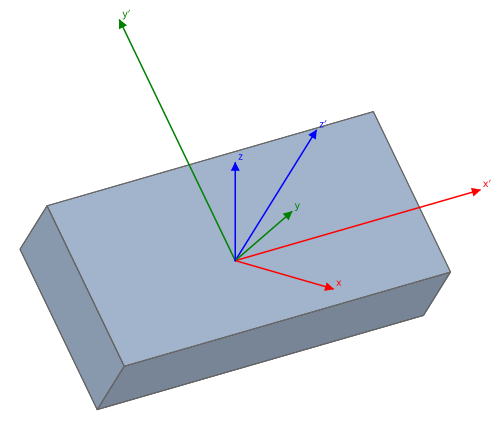

In [7]:
scene = Scene()
scene.add(box, fill="lightsteelblue", frame=True)
scene.add_frame(length=0.6)  # the world axes x, y, z at the origin, for comparison
scene

## 3. Anchors

Anchors are named points on a geometry, as in TikZ. For shapes and groups they combine
left/right (x'), front/back (y') and bottom/top (z'); lines use `start`, `midway`, `end`,
`near start` and `near end`. Anchors move and turn with the geometry.

`place(anchor, at=point)` moves a geometry so that one of its anchors sits on a point:

In [8]:
table = Box([0, 0, 0], size=[2, 1, 0.1], anchor="bottom")
print("top of the table:     ", table.anchor("top"))
print("a corner:             ", table.anchor("top front left"))

book = Box([0, 0, 0], size=[0.5, 0.35, 0.06])
book.rotate("z'", 20, about="center")
book.place("bottom", at=table.anchor("top"))
print("book lies on the table:", book.anchor("bottom"))

edge = Line(table.anchor("top front left"), table.anchor("top front right"))
print("three quarters along: ", edge.anchor("near end"))

top of the table:      [0.  0.  0.1]
a corner:              [-1.  -0.5  0.1]
book lies on the table: [0.  0.  0.1]
three quarters along:  [ 0.5 -0.5  0.1]


## 4. Scenes and styles

Geometry does not know how it is drawn. A `Scene` collects geometries with their `Style`
(fill, stroke, opacity, line width, dashes, arrows, labels). `scene.add` returns the
geometry, so creating and adding fit on one line. Styles combine with `|`.

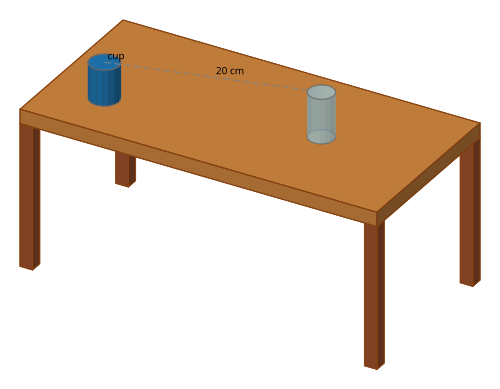

In [9]:
wood = Style(fill="peru", stroke="saddlebrown")

scene = Scene()
table = scene.add(Box([0, 0, 0.8], size=[2, 1, 0.08], anchor="bottom"), wood)
for corner in ("front left", "front right", "back left", "back right"):
    leg = Box(table.anchor(f"bottom {corner}"), size=[0.07, 0.07, 0.8], anchor=f"top {corner}")
    scene.add(leg, wood | Style(fill="sienna"))

cup = scene.add(Cylinder(table.anchor("top front left") + [0.3, 0.3, 0], radius=0.08, height=0.2), fill="C0")
scene.label(cup, "cup", at="top")
glass = scene.add(
    Cylinder(table.anchor("top") + [0.4, 0, 0], radius=0.07, height=0.25), fill="lightblue", opacity=0.5
)
scene.add(
    Line(cup.anchor("top"), glass.anchor("top")),
    stroke="gray",
    dash="dashed",
    label="20 cm",
    label_at="midway",
)
scene

### The same scene with all backends

* **SVG** (above, and `scene.render("svg")`): a vector drawing like a TikZ picture; `.save("scene.svg")`.
* **TikZ**: the same drawing as code for LaTeX documents; `scene.save("scene.tex")`.
* **matplotlib**: a 3D axes you can combine with other plots; the view can be rotated in interactive backends.
* **plotly**: interactive in the browser and in Jupyter; `.write_html("scene.html")` saves it.
* **raytrace**: an image with light, cast shadows, exact spheres and cylinders, and true
  transparency; `.save("scene.png")`. Hidden lines stay hidden, also where solids intersect.
* **mitsuba** (optional): a physically based renderer with soft light from the surroundings.

All of them take the same view options: `elev`, `azim` and `vertical_axis`.

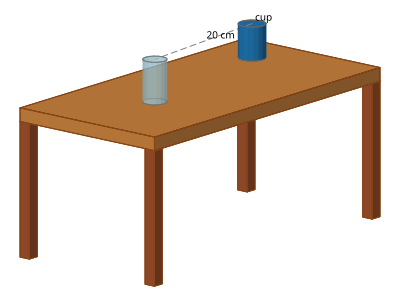

In [10]:
scene.render("svg", elev=15, azim=40, width=400)

In [11]:
print(scene.render("tikz").code[:400], "...")

% made with minigeo; needs \usepackage{tikz} and \usetikzlibrary{arrows.meta}
\begin{tikzpicture}[line join=round, line cap=round]
\definecolor{mgsienna}{RGB}{160,82,45}
\definecolor{mgsaddlebrown}{RGB}{139,69,19}
\definecolor{mgperu}{RGB}{205,133,63}
\definecolor{mgC0}{RGB}{31,119,180}
\definecolor{mgdimgray}{RGB}{105,105,105}
\definecolor{mggray}{RGB}{128,128,128}
\definecolor{mglightblue}{RGB}{ ...


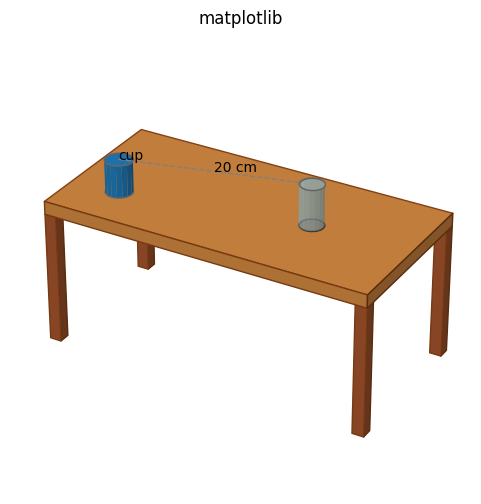

In [12]:
import matplotlib.pyplot as plt

ax = scene.render("matplotlib", show_axes=False)
ax.set_title("matplotlib")
plt.show()

In [13]:
scene.render("plotly", height=400)

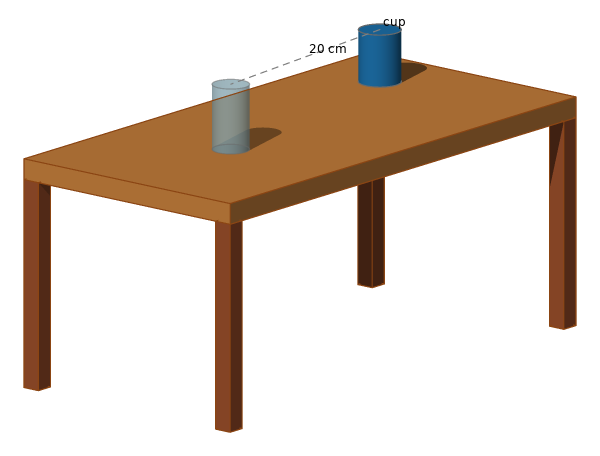

In [14]:
scene.render("raytrace", elev=15, azim=40, width=600)

The ray tracer has *looks* for diagrams rather than photos: `"soft"`, `"cel"` (a few
shading bands), `"diagram"` (outlines and soft corners) and `"print"` (gray tones).

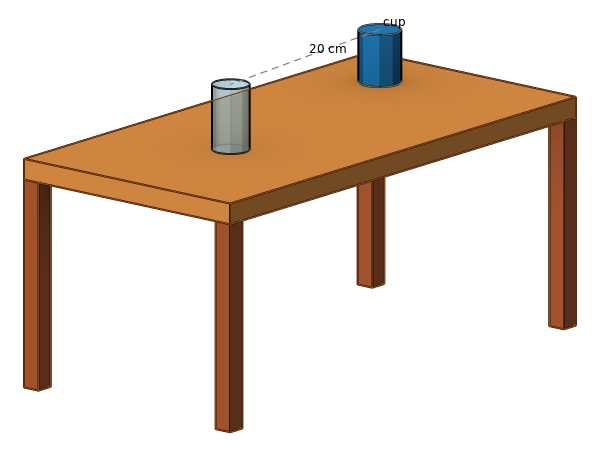

In [15]:
scene.render("raytrace", elev=15, azim=40, width=600, look="diagram")

[Mitsuba 3](https://www.mitsuba-renderer.org/) is not part of `minigeo[all]`, as it sets
its CPU or GPU variant for the whole Python process; install it with
`pip install "minigeo[mitsuba]"`. The picture matches the ray tracer's, with light that bounces
between surfaces. More light paths per pixel (`spp`) mean less noise.

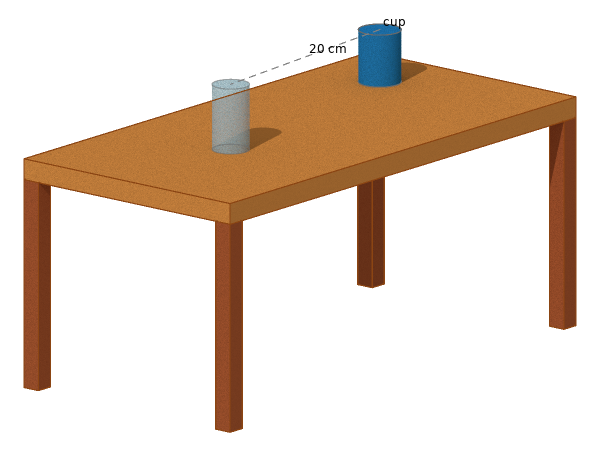

In [16]:
import importlib.util

if importlib.util.find_spec("mitsuba") is None:
    print('Mitsuba is optional: pip install "minigeo[mitsuba]"')
else:
    display(scene.render("mitsuba", elev=15, azim=40, width=600, spp=64))

### Understanding a transform

Seeing a shape before and after a transform helps to understand it. The original box is drawn
transparent, the rotated copy solid, and the rotation axis as an arrow.

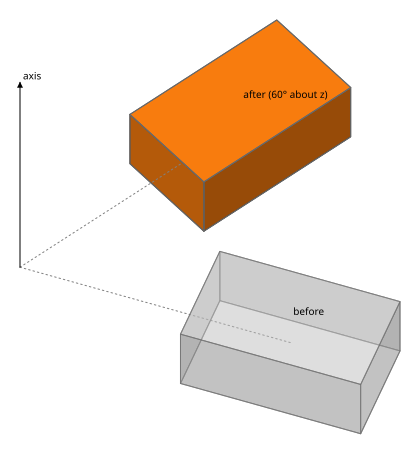

In [17]:
before = Box([1.5, 0, 0], size=[1, 0.6, 0.4])
after = before.copy()  # an independent copy, so `before` stays where it is
rotation_axis = np.array([0, 0, 1])
after.rotate(rotation_axis, 60, about=[0, 0, 0])

scene = Scene()
scene.add(before, fill="lightgray", opacity=0.4, label="before", label_at="top")
scene.add(after, fill="C1", label="after (60° about z)", label_at="top")
scene.add(Axis(rotation_axis, length=1.5), stroke="black", label="axis", label_at="end")
scene.add(Line([0, 0, 0], before.center), stroke="gray", dash="dotted")
scene.add(Line([0, 0, 0], after.center), stroke="gray", dash="dotted")
scene.render("svg", elev=50, azim=-70, width=420)

A sequence of small pictures shows how a rotation develops — here a box turning about its
own tilted axis, step by step:

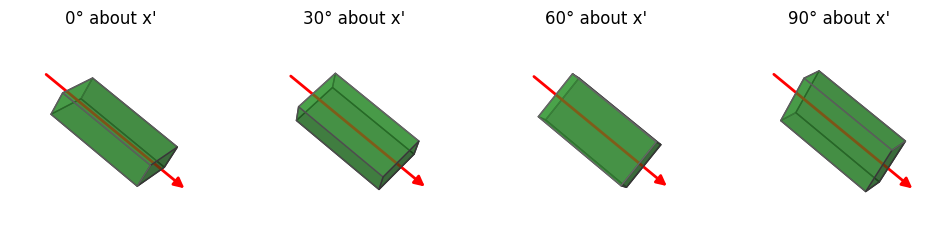

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), subplot_kw={"projection": "3d"})
box = Box([0, 0, 0], size=[1.2, 0.6, 0.3])
box.rotate("y", 30, about="center")
for step, ax in enumerate(axes):
    scene = Scene()
    scene.add(box, fill="C2", opacity=0.6)  # translucent, so the axis shows through
    scene.add(Axis(box.axes[0], origin=box.center - box.axes[0], length=2), stroke="red", line_width=2)
    scene.render("matplotlib", ax=ax, show_axes=False, elev=20, azim=-60)
    ax.set_title(f"{30 * step}° about x'")
    box.rotate("x'", 30, about="center")
plt.show()

## 5. Vectors, planes, angles and dimensions

A `Vector` is an arrow that also does vector algebra: `+`, `-`, scaling, `dot`, `cross`,
`angle_to` and `projected_onto`. Results start at the first vector's origin, so they can be
drawn right away. `Angle` draws the arc between two rays (a right angle gets a square), and
labels of vectors and angles go to sensible places by default.

Text between `$` signs is math, written as in LaTeX. Every backend shows it: SVG and the ray
tracer draw it with matplotlib's mathtext, TikZ hands it to LaTeX.

a · b = 1.68,  angle = 60.9°


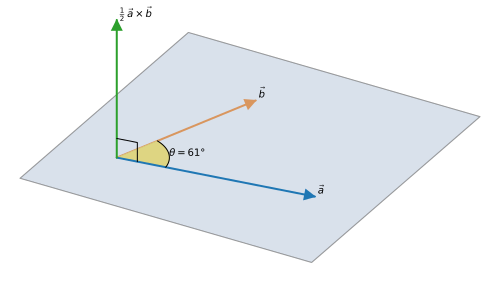

In [19]:
a = Vector([2, 0.3, 0])
b = Vector([0.6, 1.6, 0])
angle = a.angle_to(b)
print(f"a · b = {a.dot(b):.2f},  angle = {angle:.1f}°")

scene = Scene()
scene.add(Plane([1, 0.8, 0], normal=[0, 0, 1], size=3.2), fill="lightsteelblue")
scene.add(a, stroke="C0", line_width=2, label=r"$\vec{a}$")
scene.add(b, stroke="C1", line_width=2, label=r"$\vec{b}$")
scene.add(a.cross(b) / 2, stroke="C2", line_width=2, label=r"$\frac{1}{2}\,\vec{a} \times \vec{b}$")
scene.add(Angle.between(a, b, radius=0.5), fill="khaki", label=rf"$\theta = {angle:.0f}°$")
scene.add(Angle.between(a, a.cross(b), radius=0.3))  # a right angle
scene

A `Plane` is drawn as a translucent patch. It knows distances, projections and intersections —
here a point is projected onto the ground plane, and a `Dimension` shows its height.

height above the plane: 1.2


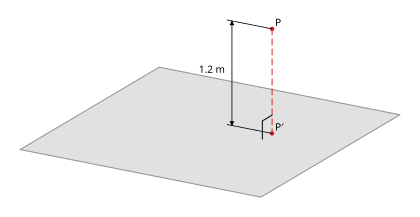

In [20]:
ground = Plane([0, 0, 0], normal=[0, 0, 1], size=3)
p = np.array([0.6, 0.3, 1.2])
foot = ground.project(p)
print("height above the plane:", ground.distance_to(p))

scene = Scene()
scene.add(ground, fill="lightgray")
scene.add(Point(p), fill="C3", label="P")
scene.add(Point(foot), fill="C3", label="P′")
scene.add(Line(p, foot), stroke="C3", dash="dashed")
scene.add(Angle(foot, p, foot + [0, -1, 0], radius=0.3))
scene.add(Dimension(foot, p, offset=[-0.5, 0, 0], unit=" m"))
scene.render("svg", elev=20, width=420)

Dimension lines work on any two points, for example the edges of a box:

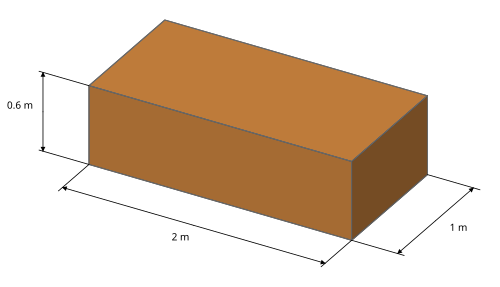

In [21]:
box = Box([0, 0, 0], size=(2, 1, 0.6), anchor="bottom")
scene = Scene()
scene.add(box, fill="peru")
scene.add(
    Dimension(
        box.anchor("bottom front left"), box.anchor("bottom front right"), offset=[0, -0.35, 0], unit=" m"
    )
)
scene.add(
    Dimension(
        box.anchor("bottom front right"), box.anchor("bottom back right"), offset=[0.35, 0, 0], unit=" m"
    )
)
scene.add(
    Dimension(box.anchor("bottom front left"), box.anchor("top front left"), offset=[-0.35, 0, 0], unit=" m")
)
scene

## 6. Curves and meshes

A `Polyline` goes through points in order; a `Curve` draws any function of one parameter `t`.
Their anchors are measured along their length, and `curve.at(t)` and `curve.tangent_at(t)`
give exact points and directions, also after transforms.

length of the helix: 12.705


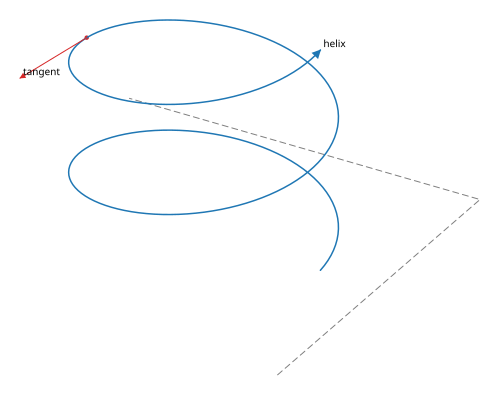

In [22]:
helix = Curve(lambda t: (np.cos(t), np.sin(t), 0.15 * t), t=(0, 4 * np.pi), samples=200)
path = Polyline([[1.5, -1.5, 0], [1.5, 1.5, 0], [-1.5, 1.5, 0]])
t = 3 * np.pi

scene = Scene()
scene.add(helix, stroke="C0", line_width=1.5, arrow=True, label="helix")
scene.add(path, stroke="gray", dash="dashed")
scene.add(Point(helix.at(t)), fill="C3")
scene.add(Vector(helix.tangent_at(t), origin=helix.at(t)), stroke="C3", label="tangent")
print(f"length of the helix: {helix.length:.3f}")
scene

A `Mesh` is a shape made of any faces, given as vertex indices. A closed mesh has a `volume`;
only its sharp edges get an outline, so a smooth surface shows its shape and not its grid.
Here a grid of points makes the graph of a function:

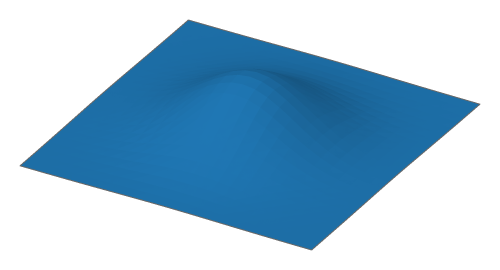

In [23]:
n = 25
x, y = np.meshgrid(np.linspace(-2, 2, n), np.linspace(-2, 2, n))
z = 0.8 * np.exp(-(x**2 + y**2))
points = np.column_stack([x.ravel(), y.ravel(), z.ravel()])
squares = [
    [i * n + j, i * n + j + 1, (i + 1) * n + j + 1, (i + 1) * n + j]
    for i in range(n - 1)
    for j in range(n - 1)
]

scene = Scene()
bump = scene.add(Mesh(points, squares), fill="C0")
scene.render("raytrace", width=500, look="soft")

Meshes come from and go to other 3D programs as OBJ or STL files, with numpy only.
`scene.save` writes every shape of a scene (OBJ with colors in a `.mtl` file), and `read_mesh`
reads a file as a mesh:

In [24]:
import tempfile
from pathlib import Path

folder = Path(tempfile.mkdtemp())
scene.save(folder / "bump.stl")
again = read_mesh(folder / "bump.stl")
print(again)

Open mesh at [0.         0.         0.40013419] with 625 vertices and 1152 faces


## 7. Lines through shapes

`shape.intersect(line)` returns where a line meets a shape, sorted along the line. Spheres
and cylinders are met exactly, other shapes at their faces. The line counts as infinite;
`segment=True` keeps only the points between its ends.

[[1.403 0.055 0.173]
 [2.533 0.209 0.379]]


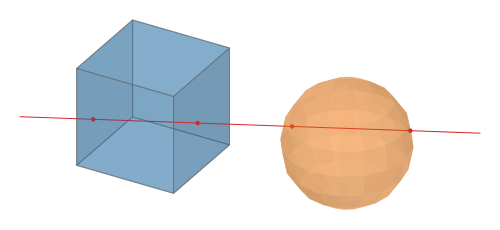

In [25]:
box = Box([0, 0, 0], size=1)
ball = Sphere([2, 0, 0.2], radius=0.6)
ray = Line([-1.2, -0.3, -0.3], [3.2, 0.3, 0.5])

scene = Scene()
scene.add(box, fill="C0", opacity=0.3)
scene.add(ball, fill="C1", opacity=0.3)
scene.add(ray, stroke="C3")
for shape in (box, ball):
    for point in shape.intersect(ray):
        scene.add(Point(point), fill="C3")
print(ball.intersect(ray).round(3))
scene

## 8. Axes, grids and layers

`Axes` draws coordinate axes with numbered ticks, and `axes.grid("xy")` a matching grid.
Everything in a scene sits on a *layer* (`"main"` unless `layer=` says otherwise): layers can
be hidden and shown again (`scene.hide`, `scene.show`), and `scene.remove(geometry)` takes a single geometry out.

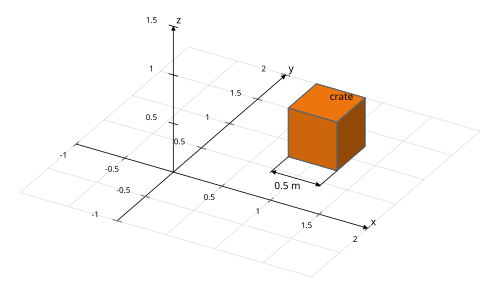

In [26]:
axes = Axes(low=[-1, -1, 0], high=[2, 2, 1.5], step=0.5)

scene = Scene()
scene.add(axes, layer="axes")
scene.add(axes.grid("xy"), layer="axes")
crate = scene.add(Box([1, 1, 0], size=0.5, anchor="bottom"), fill="C1", label="crate", label_at="top")
front = (crate.anchor("bottom front left"), crate.anchor("bottom front right"))
scene.add(Dimension(*front, offset=[0, -0.3, 0], unit=" m"), layer="dimensions")
scene

['axes', 'main', 'dimensions'] hidden: {'dimensions'}


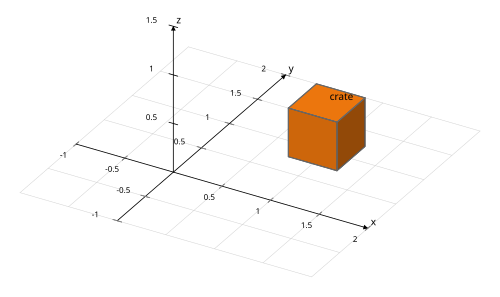

In [27]:
scene.hide("dimensions")
print(scene.layers, "hidden:", scene.hidden)
scene

## More

* `animations.ipynb`: animations with plotly, matplotlib and the ray tracer
* `joints.ipynb`: frames and joints, e.g. an XYZ stage and a θ–2θ diffractometer
* `Cristallina.ipynb`: a sketch of an X-ray scattering experiment, with x pointing up
* The [manual](https://minigeo.readthedocs.io/en/latest/manual/index.html) introduces each idea
  with code next to its picture.